# RehaTrack 2.8 — Açıklanabilir Rehabilitasyon İzlem Prototipi

**Amaç:** Rehabilitasyon ölçümlerindeki zaman içi değişimleri görselleştiren ve önceden tanımlanmış örnek kurallara göre fizyoterapistin yeniden değerlendirmeyi düşünmesine yardımcı olan bir eğitim/araştırma prototipi.

> **Önemli sınır:** Bu notebook sentetik (uydurulmuş) veriler kullanır. Kurallar klinik olarak doğrulanmış eşikler değildir; sistem tanı koymaz, tedavi önermez ve gerçek hasta bakımında kullanılmamalıdır. Klinik kullanımdan önce uzman görüşü, etik/onay süreçleri ve gerçek verilerle doğrulama gerekir.


## 1. Kütüphaneler ve örnek veri

Her satır bir hastanın belirli bir tarihteki değerlendirmesini temsil eder. Ölçümler örnek amaçlıdır:
- **Pain_NRS:** 0–10 ağrı puanı (yüksek daha fazla ağrı)
- **Knee_ROM_deg:** örnek diz fleksiyon hareket açıklığı (derece; yüksek genellikle daha geniş hareket)
- **Function_score:** 0–100 örnek işlev puanı (yüksek daha iyi işlev)
- **Exercise_adherence_pct:** hastanın bildirdiği egzersiz uyumu (%)

Gerçek uygulamada ölçüm araçları, puan aralıkları, klinik olarak anlamlı değişimler ve eksik veri kuralları alan uzmanları tarafından tanımlanmalıdır.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Tamamen sentetik örnek veri; gerçek hasta verisi değildir.
data = [
    # patient_id, week, pain, ROM, function, adherence
    ("P001", 0, 7, 85, 35, 45),
    ("P001", 2, 6, 92, 42, 55),
    ("P001", 4, 4, 105, 56, 70),
    ("P001", 6, 3, 112, 65, 78),

    ("P002", 0, 4, 105, 62, 75),
    ("P002", 2, 3, 110, 66, 80),
    ("P002", 4, 5, 106, 60, 50),
    ("P002", 6, 6, 100, 52, 40),

    ("P003", 0, 6, 90, 40, 50),
    ("P003", 2, 5, 96, 47, 60),
    ("P003", 4, 5, 98, 48, 62),
    ("P003", 6, 4, 103, 55, 68),
]

df = pd.DataFrame(
    data,
    columns=[
        "patient_id", "week", "Pain_NRS", "Knee_ROM_deg",
        "Function_score", "Exercise_adherence_pct"
    ]
)

display(df.head(12))
print(f"Satır sayısı: {len(df)} | Örnek hasta sayısı: {df['patient_id'].nunique()}")

,patient_id,week,Pain_NRS,Knee_ROM_deg,Function_score,Exercise_adherence_pct
0,P001,0,7,85,35,45
1,P001,2,6,92,42,55
2,P001,4,4,105,56,70
3,P001,6,3,112,65,78
4,P002,0,4,105,62,75
5,P002,2,3,110,66,80
6,P002,4,5,106,60,50
7,P002,6,6,100,52,40
8,P003,0,6,90,40,50
9,P003,2,5,96,47,60


Satır sayısı: 12 | Örnek hasta sayısı: 3


## 2. Hasta seçimi ve zaman içi grafik

Grafikler, bir hastanın ölçümlerinin zaman içinde nasıl değiştiğini göstermeye yarar. Tek başına grafikler klinik karar yerine geçmez.


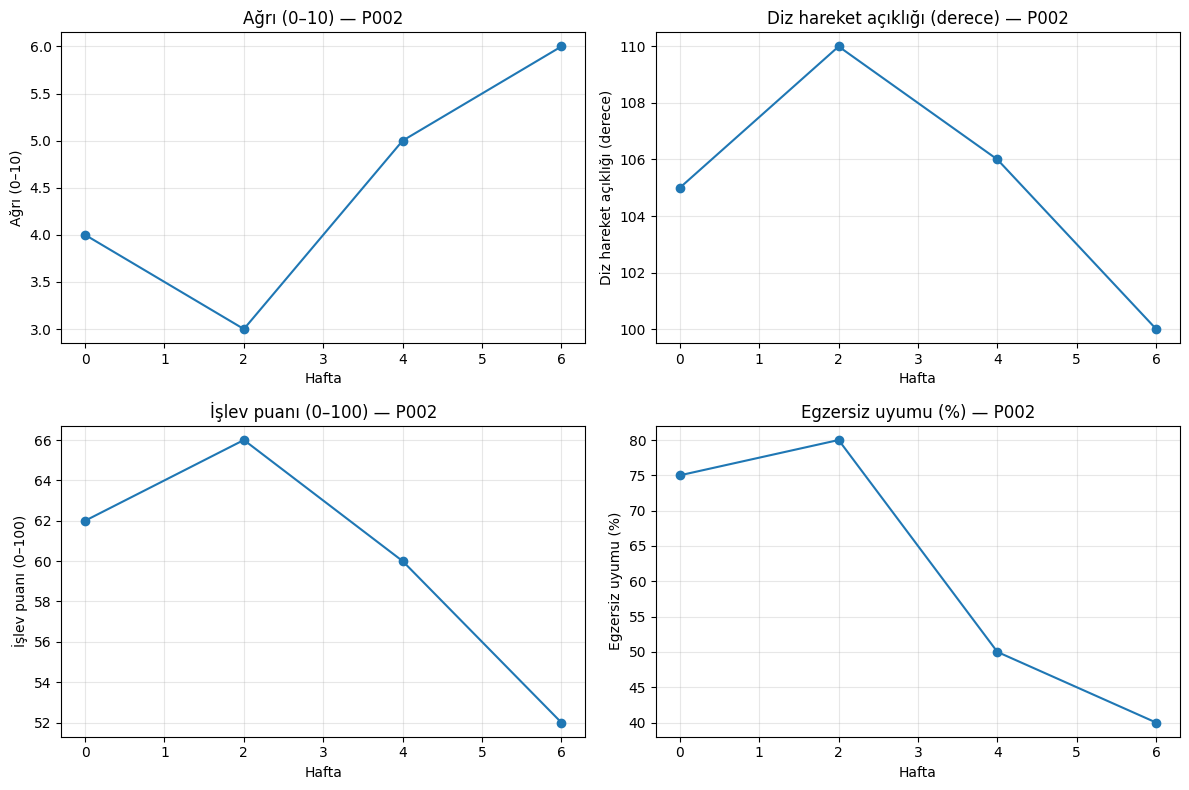

,patient_id,week,Pain_NRS,Knee_ROM_deg,Function_score,Exercise_adherence_pct
4,P002,0,4,105,62,75
5,P002,2,3,110,66,80
6,P002,4,5,106,60,50
7,P002,6,6,100,52,40


In [ ]:
patient_ids = sorted(df["patient_id"].unique())
selected_patient = "P001"  # İstersen P001 veya P003 olarak değiştir
patient_df = df[df["patient_id"] == selected_patient].sort_values("week")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

charts = [
    ("Pain_NRS", "Ağrı (0–10)", axes[0, 0]),
    ("Knee_ROM_deg", "Diz hareket açıklığı (derece)", axes[0, 1]),
    ("Function_score", "İşlev puanı (0–100)", axes[1, 0]),
    ("Exercise_adherence_pct", "Egzersiz uyumu (%)", axes[1, 1]),
]

for column, title, ax in charts:
    ax.plot(patient_df["week"], patient_df[column], marker="o")
    ax.set_title(f"{title} — {selected_patient}")
    ax.set_xlabel("Hafta")
    ax.set_ylabel(title)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

display(patient_df)

## 3. Açıklanabilir uyarı kuralları

Aşağıdaki eşikler **yalnızca prototip davranışını göstermek için seçilmiştir**; klinik eşik veya kılavuz olarak yorumlanmamalıdır. Her uyarı, hangi verinin hangi örnek kurala takıldığını açıklar. Kural tabanlı sistem, makine öğrenmesi modeli değildir.


In [ ]:
def review_flags(patient_history: pd.DataFrame) -> list[str]:
    """Örnek kural tabanlı inceleme bayrakları üretir; tanı koymaz."""
    history = patient_history.sort_values("week")
    if len(history) < 2:
        return ["Yorum için en az iki değerlendirme kaydı gerekir."]

    previous = history.iloc[-2]
    latest = history.iloc[-1]
    flags = []

    # Demo eşikleri; klinik olarak doğrulanmış değildir.
    if latest["Pain_NRS"] - previous["Pain_NRS"] >= 2:
        flags.append(
            f"Ağrı puanı son ölçümde {previous['Pain_NRS']} değerinden "
            f"{latest['Pain_NRS']} değerine yükseldi."
        )

    if previous["Function_score"] - latest["Function_score"] >= 10:
        flags.append(
            f"İşlev puanı son ölçümde {previous['Function_score']} değerinden "
            f"{latest['Function_score']} değerine düştü."
        )

    if previous["Knee_ROM_deg"] - latest["Knee_ROM_deg"] >= 10:
        flags.append(
            f"Hareket açıklığı son ölçümde {previous['Knee_ROM_deg']}° değerinden "
            f"{latest['Knee_ROM_deg']}° değerine azaldı."
        )

    if latest["Exercise_adherence_pct"] < 50:
        flags.append(
            f"Bildirilen egzersiz uyumu %{latest['Exercise_adherence_pct']}; "
            "engellerin klinik görüşmede değerlendirilmesi düşünülebilir."
        )

    if not flags:
        flags.append(
            "Tanımlı örnek kurallar tetiklenmedi. Bu, klinik sorun olmadığı anlamına gelmez."
        )

    return flags


flags = review_flags(patient_df)
print(f"RehaTrack örnek inceleme çıktısı — {selected_patient}")
for i, flag in enumerate(flags, start=1):
    print(f"{i}. {flag}")

print("\nNot: Çıktı klinik karar değildir; fizyoterapistin değerlendirmesinin yerini almaz.")

RehaTrack örnek inceleme çıktısı — P002
1. Bildirilen egzersiz uyumu %40; engellerin klinik görüşmede değerlendirilmesi düşünülebilir.

Not: Çıktı klinik karar değildir; fizyoterapistin değerlendirmesinin yerini almaz.


## 4. Basit otomatik özet

Bu bölüm ölçümlerin ilk ve son değerlerini karşılaştırır. İyileşme yüzdesi gibi klinik anlamı olabilecek bir skor üretmiyoruz; yalnızca ham değişimi raporluyoruz.


In [ ]:
def make_summary(patient_history: pd.DataFrame) -> pd.DataFrame:
    history = patient_history.sort_values("week")
    first = history.iloc[0]
    last = history.iloc[-1]

    metrics = [
        ("Ağrı (0–10)", "Pain_NRS"),
        ("Diz hareket açıklığı (derece)", "Knee_ROM_deg"),
        ("İşlev puanı (0–100)", "Function_score"),
        ("Egzersiz uyumu (%)", "Exercise_adherence_pct"),
    ]

    rows = []
    for label, col in metrics:
        rows.append({
            "Ölçüm": label,
            "İlk kayıt": first[col],
            "Son kayıt": last[col],
            "Ham değişim (son - ilk)": last[col] - first[col],
        })
    return pd.DataFrame(rows)

summary = make_summary(patient_df)
display(summary)

,Ölçüm,İlk kayıt,Son kayıt,Ham değişim (son - ilk)
0,Ağrı (0–10),4,6,2
1,Diz hareket açıklığı (derece),105,100,-5
2,İşlev puanı (0–100),62,52,-10
3,Egzersiz uyumu (%),75,40,-35


## 5. Mülakatta araştırma planı olarak nasıl anlatılır?

**Araştırma sorusu:** Çok boyutlu rehabilitasyon ölçümlerindeki zaman içi değişimleri açıklanabilir kurallarla özetleyen bir sistem, fizyoterapistin yeniden değerlendirme gerektirebilecek örüntüleri fark etmesini destekleyebilir mi?

**Sonraki aşamalar:**
1. Klinik uzmanlarla gereksinim analizi ve ölçüm setini belirleme.
2. Ölçüm tanımlarını, eşikleri ve uyarı mantığını literatür ve uzman görüşüyle gerekçelendirme.
3. Etik kurul ve veri yönetişimi gereklilikleri sağlandıktan sonra uygun, kimliksizleştirilmiş verilerle değerlendirme.
4. Uyarıların duyarlılık, özgüllük, yanlış alarm oranı ve klinisyen kullanılabilirliği açısından incelenmesi.
5. Eksik veri, farklı hasta gruplarında performans ve olası yanlılıkların değerlendirilmesi.

**Prototipin mevcut sınırlılıkları:** Sentetik veri, küçük örneklem, örnek eşikler, dış doğrulama olmaması ve gerçek klinik sonuçlarla ilişkilendirilmemiş uyarılar. Bu nedenle performans veya klinik fayda iddiasında bulunulamaz.


In [ ]:

# RehaTrack 2.1 — Çok boyutlu değişim analizi
# Önceki hücrelerde oluşturduğumuz df tablosunu kullanır.

import pandas as pd

metrics = {
    "Pain_NRS": {
        "name": "Ağrı",
        "unit": "puan",
        "direction": "lower"
    },
    "Knee_ROM_deg": {
        "name": "Diz hareket açıklığı",
        "unit": "derece",
        "direction": "higher"
    },
    "Function_score": {
        "name": "Fonksiyon",
        "unit": "puan",
        "direction": "higher"
    },
    "Exercise_adherence_pct": {
        "name": "Egzersiz uyumu",
        "unit": "%",
        "direction": "higher"
    }
}

def analyze_patient(df, patient_id):
    patient = df[df["patient_id"] == patient_id].copy()
    patient = patient.sort_values("week")

    if len(patient) < 2:
        print("Karşılaştırma için en az iki değerlendirme gerekir.")
        return None

    first = patient.iloc[0]
    last = patient.iloc[-1]
    results = []

    for column, info in metrics.items():
        start = first[column]
        end = last[column]

        if pd.isna(start) or pd.isna(end):
            change = None
            interpretation = "Eksik veri — karşılaştırılamıyor"
        else:
            change = end - start

            if change == 0:
                interpretation = "Değişim yok"
            elif info["direction"] == "lower":
                interpretation = (
                    "Olumlu yönde değişim"
                    if change < 0 else "Olumsuz yönde değişim"
                )
            else:
                interpretation = (
                    "Olumlu yönde değişim"
                    if change > 0 else "Olumsuz yönde değişim"
                )

        results.append({
            "Ölçüm": info["name"],
            "Başlangıç": start,
            "Son": end,
            "Ham değişim": change,
            "Birim": info["unit"],
            "Yön değerlendirmesi": interpretation
        })

    return pd.DataFrame(results)


# Örnek hastayı değiştirerek deneyebilirsin: P001, P002 veya P003
selected_patient = "P002"

report = analyze_patient(df, selected_patient)

if report is not None:
    print(f"RehaTrack değişim raporu: {selected_patient}")
    display(report)


RehaTrack değişim raporu: P002


,Ölçüm,Başlangıç,Son,Ham değişim,Birim,Yön değerlendirmesi
0,Ağrı,4,6,2,puan,Olumsuz yönde değişim
1,Diz hareket açıklığı,105,100,-5,derece,Olumsuz yönde değişim
2,Fonksiyon,62,52,-10,puan,Olumsuz yönde değişim
3,Egzersiz uyumu,75,40,-35,%,Olumsuz yönde değişim


In [ ]:

# RehaTrack 2.2 — Eğilim, veri kalitesi ve çok boyutlu inceleme

import pandas as pd

def analyze_trends(df, patient_id):
    patient = (
        df[df["patient_id"] == patient_id]
        .sort_values("week")
        .copy()
    )

    if patient.empty:
        print("Bu hasta için kayıt bulunamadı.")
        return

    metrics = {
        "Pain_NRS": ("Ağrı", "lower"),
        "Knee_ROM_deg": ("Diz hareket açıklığı", "higher"),
        "Function_score": ("Fonksiyon", "higher"),
        "Exercise_adherence_pct": ("Egzersiz uyumu", "higher")
    }

    print(f"REHATRACK 2.2 | Hasta: {patient_id}")
    print("=" * 55)

    # 1. Veri kalitesi kontrolü
    print("\n1. VERİ KALİTESİ")

    if patient["week"].duplicated().any():
        print("Uyarı: Aynı haftada birden fazla kayıt var.")
    else:
        print("Hafta alanında yinelenen kayıt yok.")

    for col in metrics:
        missing = patient[col].isna().sum()
        print(f"{metrics[col][0]}: {missing} eksik ölçüm")

    # 2. Eğilim analizi
    print("\n2. ZAMAN İÇİNDE EĞİLİM")
    print("Eğilim, haftaya göre basit doğrusal eğimle hesaplanır.")

    slopes = {}

    for col, (name, direction) in metrics.items():
        valid = patient[["week", col]].dropna()

        if len(valid) < 2 or valid["week"].nunique() < 2:
            print(f"{name}: Eğilim hesaplamak için yeterli veri yok.")
            slopes[col] = None
            continue

        slope = (
            valid["week"].corr(valid[col])
            if valid["week"].std() > 0 and valid[col].std() > 0
            else 0
        )

        # Birim/hafta cinsinden doğrusal eğim
        from scipy.stats import linregress
        result = linregress(valid["week"], valid[col])
        slope_per_week = result.slope
        slopes[col] = slope_per_week

        if abs(slope_per_week) < 0.01:
            trend = "Belirgin yönlü değişim görülmüyor"
        elif (direction == "lower" and slope_per_week < 0) or (
            direction == "higher" and slope_per_week > 0
        ):
            trend = "Olumlu yönde eğilim"
        else:
            trend = "Olumsuz yönde eğilim"

        print(
            f"{name}: {trend} "
            f"(eğim: {slope_per_week:.2f} birim/hafta)"
        )

    # 3. Son iki değerlendirmede çok boyutlu değişim
    print("\n3. ÇOK BOYUTLU İNCELEME")

    if len(patient) < 2:
        print("Karşılaştırma için en az iki kayıt gerekli.")
        return

    previous = patient.iloc[-2]
    latest = patient.iloc[-1]
    adverse_changes = []
    missing_comparisons = []

    for col, (name, direction) in metrics.items():
        old, new = previous[col], latest[col]

        if pd.isna(old) or pd.isna(new):
            missing_comparisons.append(name)
            continue

        change = new - old

        adverse = (
            (direction == "lower" and change > 0)
            or (direction == "higher" and change < 0)
        )

        if adverse:
            adverse_changes.append(
                f"{name}: {old:g} → {new:g}"
            )

    if missing_comparisons:
        print(
            "Karşılaştırılamayan ölçümler: "
            + ", ".join(missing_comparisons)
        )

    if len(adverse_changes) >= 2:
        print(
            "İNCELEME BAYRAĞI: Birden fazla ölçüm olumsuz yönde değişmiş."
        )
        for item in adverse_changes:
            print(" •", item)
        print(
            "Önerilen işlem: Klinik bağlamı ve ölçüm koşullarını "
            "fizyoterapist yeniden değerlendirsin."
        )
    elif len(adverse_changes) == 1:
        print("İzlenecek değişim:")
        print(" •", adverse_changes[0])
    elif not missing_comparisons:
        print(
            "Tanımlı yön kurallarına göre olumsuz değişim saptanmadı."
        )
    else:
        print("Eksik karşılaştırmalar nedeniyle sonuç sınırlı.")

    print("\nNot: Bu, eğitim amaçlı kural tabanlı prototiptir.")
    print("Eşikler klinik olarak doğrulanmamıştır; tanı koymaz.")


# Hasta seçimi
analyze_trends(df, "P001")
analyze_trends(df, "P002")
analyze_trends(df, "P003")

REHATRACK 2.2 | Hasta: P001

1. VERİ KALİTESİ
Hafta alanında yinelenen kayıt yok.
Ağrı: 0 eksik ölçüm
Diz hareket açıklığı: 0 eksik ölçüm
Fonksiyon: 0 eksik ölçüm
Egzersiz uyumu: 0 eksik ölçüm

2. ZAMAN İÇİNDE EĞİLİM
Eğilim, haftaya göre basit doğrusal eğimle hesaplanır.
Ağrı: Olumlu yönde eğilim (eğim: -0.70 birim/hafta)
Diz hareket açıklığı: Olumlu yönde eğilim (eğim: 4.70 birim/hafta)
Fonksiyon: Olumlu yönde eğilim (eğim: 5.20 birim/hafta)
Egzersiz uyumu: Olumlu yönde eğilim (eğim: 5.70 birim/hafta)

3. ÇOK BOYUTLU İNCELEME
Tanımlı yön kurallarına göre olumsuz değişim saptanmadı.

Not: Bu, eğitim amaçlı kural tabanlı prototiptir.
Eşikler klinik olarak doğrulanmamıştır; tanı koymaz.
REHATRACK 2.2 | Hasta: P002

1. VERİ KALİTESİ
Hafta alanında yinelenen kayıt yok.
Ağrı: 0 eksik ölçüm
Diz hareket açıklığı: 0 eksik ölçüm
Fonksiyon: 0 eksik ölçüm
Egzersiz uyumu: 0 eksik ölçüm

2. ZAMAN İÇİNDE EĞİLİM
Eğilim, haftaya göre basit doğrusal eğimle hesaplanır.
Ağrı: Olumsuz yönde eğilim (eğim: 

In [ ]:

import pandas as pd

# RehaTrack 2.3 — Veri kalitesi kontrolleri

def validate_rehatrack_data(data):
    issues = []

    required = [
        "patient_id", "week", "Pain_NRS", "Knee_ROM_deg",
        "Function_score", "Exercise_adherence_pct"
    ]

    missing_columns = [c for c in required if c not in data.columns]
    if missing_columns:
        return [f"Eksik sütun: {c}" for c in missing_columns]

    if data["patient_id"].isna().any():
        issues.append("Hasta kimliği eksik.")

    for col in required:
        missing = data[col].isna().sum()
        if missing:
            issues.append(f"{col}: {missing} eksik değer.")

    if data[["patient_id", "week"]].duplicated().any():
        issues.append("Aynı hasta ve haftada yinelenen kayıt var.")

    ranges = {
        "week": (0, 100),
        "Pain_NRS": (0, 10),
        "Knee_ROM_deg": (0, 180),
        "Function_score": (0, 100),
        "Exercise_adherence_pct": (0, 100)
    }

    for col, (low, high) in ranges.items():
        values = pd.to_numeric(data[col], errors="coerce")
        invalid = values.notna() & (
            (values < low) | (values > high)
        )
        if invalid.any():
            issues.append(
                f"{col}: {invalid.sum()} değer izin verilen "
                f"{low}–{high} aralığının dışında."
            )

    if not issues:
        issues.append("Temel veri kontrollerinde sorun bulunmadı.")

    return issues


print("MEVCUT VERİ KONTROLÜ")
for issue in validate_rehatrack_data(df):
    print("-", issue)


# İki değerlendirme arasındaki olumsuz değişimleri say
def count_adverse_changes(history):
    history = history.sort_values("week")

    if len(history) < 2:
        return None, "En az iki kayıt gerekli."

    previous = history.iloc[-2]
    latest = history.iloc[-1]

    directions = {
        "Pain_NRS": "lower",
        "Knee_ROM_deg": "higher",
        "Function_score": "higher",
        "Exercise_adherence_pct": "higher"
    }

    adverse = []
    missing = []

    for col, direction in directions.items():
        old, new = previous[col], latest[col]

        if pd.isna(old) or pd.isna(new):
            missing.append(col)
            continue

        is_adverse = (
            (direction == "lower" and new > old)
            or (direction == "higher" and new < old)
        )

        if is_adverse:
            adverse.append(col)

    if missing:
        return len(adverse), (
            "Eksik verili karşılaştırma: " + ", ".join(missing)
        )

    if len(adverse) >= 2:
        return len(adverse), "Çok boyutlu inceleme bayrağı"

    return len(adverse), "Çok boyutlu bayrak tetiklenmedi"


# Sentetik senaryolarla mantık testi
scenarios = {
    "Olumlu değişim": pd.DataFrame([
        [0, 7, 80, 30, 40],
        [2, 5, 95, 45, 60]
    ], columns=[
        "week", "Pain_NRS", "Knee_ROM_deg",
        "Function_score", "Exercise_adherence_pct"
    ]),

    "Olumsuz değişim": pd.DataFrame([
        [0, 4, 110, 70, 80],
        [2, 6, 100, 55, 45]
    ], columns=[
        "week", "Pain_NRS", "Knee_ROM_deg",
        "Function_score", "Exercise_adherence_pct"
    ]),

    "Eksik ölçüm": pd.DataFrame([
        [0, 4, 110, 70, 80],
        [2, 6, None, 55, 45]
    ], columns=[
        "week", "Pain_NRS", "Knee_ROM_deg",
        "Function_score", "Exercise_adherence_pct"
    ])
}

print("\nKARAR KURALI TESTLERİ")

for name, scenario in scenarios.items():
    count, message = count_adverse_changes(scenario)
    print(f"\nSenaryo: {name}")
    print(f"Olumsuz değişim sayısı: {count}")
    print(f"Çıktı: {message}")

print("\nBu testler yazılım mantığını sınar; klinik doğrulama değildir.")


MEVCUT VERİ KONTROLÜ
- Temel veri kontrollerinde sorun bulunmadı.

KARAR KURALI TESTLERİ

Senaryo: Olumlu değişim
Olumsuz değişim sayısı: 0
Çıktı: Çok boyutlu bayrak tetiklenmedi

Senaryo: Olumsuz değişim
Olumsuz değişim sayısı: 4
Çıktı: Çok boyutlu inceleme bayrağı

Senaryo: Eksik ölçüm
Olumsuz değişim sayısı: 3
Çıktı: Eksik verili karşılaştırma: Knee_ROM_deg

Bu testler yazılım mantığını sınar; klinik doğrulama değildir.


In [ ]:

# RehaTrack 2.4 — Otomatik yazılım testleri

def run_rehatrack_tests():
    test_results = []

    # Test 1: Olumlu değişim
    good = scenarios["Olumlu değişim"]
    count, message = count_adverse_changes(good)

    test_results.append({
        "Test": "Olumlu değişim",
        "Beklenen": 0,
        "Gerçek": count,
        "Sonuç": "GEÇTİ" if count == 0 else "BAŞARISIZ"
    })

    # Test 2: Dört ölçümde olumsuz değişim
    bad = scenarios["Olumsuz değişim"]
    count, message = count_adverse_changes(bad)

    test_results.append({
        "Test": "Olumsuz değişim",
        "Beklenen": 4,
        "Gerçek": count,
        "Sonuç": "GEÇTİ" if count == 4 else "BAŞARISIZ"
    })

    # Test 3: Eksik veri uyarısı
    incomplete = scenarios["Eksik ölçüm"]
    count, message = count_adverse_changes(incomplete)

    missing_detected = "Eksik verili karşılaştırma" in message

    test_results.append({
        "Test": "Eksik ölçüm",
        "Beklenen": "Eksik veri bildirimi",
        "Gerçek": message,
        "Sonuç": "GEÇTİ" if missing_detected else "BAŞARISIZ"
    })

    results_df = pd.DataFrame(test_results)
    display(results_df)

    passed = (results_df["Sonuç"] == "GEÇTİ").sum()
    total = len(results_df)

    print(f"Başarılı test: {passed}/{total}")

    if passed == total:
        print("Tüm yazılım mantığı testleri geçti.")
    else:
        print("Başarısız testleri incelemek gerekiyor.")

    print("Bu sonuçlar klinik geçerliliği kanıtlamaz.")

run_rehatrack_tests()


,Test,Beklenen,Gerçek,Sonuç
0,Olumlu değişim,0,0,GEÇTİ
1,Olumsuz değişim,4,4,GEÇTİ
2,Eksik ölçüm,Eksik veri bildirimi,Eksik verili karşılaştırma: Knee_ROM_deg,GEÇTİ


Başarılı test: 3/3
Tüm yazılım mantığı testleri geçti.
Bu sonuçlar klinik geçerliliği kanıtlamaz.


In [ ]:
# RehaTrack 2.5 — Veri kalite kuralları

REQUIRED_COLUMNS = [
    "patient_id",
    "week",
    "Pain_NRS",
    "Knee_ROM_deg",
    "Function_score",
    "Exercise_adherence_pct"
]

# Yazılım testleri için örnek sınırlar.
# Bunlar klinik karar eşikleri değildir.
VALUE_RANGES = {
    "week": (0, 100),
    "Pain_NRS": (0, 10),
    "Knee_ROM_deg": (0, 180),
    "Function_score": (0, 100),
    "Exercise_adherence_pct": (0, 100)
}

print("RehaTrack 2.5 veri kalite kuralları tanımlandı.")
print("Gerekli sütun sayısı:", len(REQUIRED_COLUMNS))

RehaTrack 2.5 veri kalite kuralları tanımlandı.
Gerekli sütun sayısı: 6


In [ ]:
import pandas as pd
import numpy as np

def validate_rehatrack_data(data):
    issues = []

    # 1. Girdi kontrolü
    if not isinstance(data, pd.DataFrame):
        return pd.DataFrame([{
            "Seviye": "HATA",
            "Kontrol": "Girdi tipi",
            "Satır": "-",
            "Açıklama": "Girdi bir pandas DataFrame olmalıdır."
        }])

    # 2. Gerekli sütunlar
    missing_columns = [
        col for col in REQUIRED_COLUMNS
        if col not in data.columns
    ]

    for col in missing_columns:
        issues.append({
            "Seviye": "HATA",
            "Kontrol": "Eksik sütun",
            "Satır": "-",
            "Açıklama": f"Gerekli sütun bulunamadı: {col}"
        })

    # Eksik sütun varsa sonraki kontrollerin bir kısmı yapılamaz.
    if missing_columns:
        return pd.DataFrame(issues)

    # Orijinal veriyi değiştirmemek için kopya oluşturuyoruz.
    df = data[REQUIRED_COLUMNS].copy()

    # 3. Boş veri seti
    if df.empty:
        issues.append({
            "Seviye": "HATA",
            "Kontrol": "Boş veri seti",
            "Satır": "-",
            "Açıklama": "Kontrol edilecek kayıt bulunmuyor."
        })
        return pd.DataFrame(issues)

    # 4. Eksik değerler
    for col in REQUIRED_COLUMNS:
        missing_mask = df[col].isna()

        for idx in df.index[missing_mask]:
            issues.append({
                "Seviye": "UYARI",
                "Kontrol": "Eksik değer",
                "Satır": str(idx),
                "Açıklama": f"{col} alanı boş."
            })

    # 5. Hasta kimliği kontrolü
    patient_text = df["patient_id"].astype("string").str.strip()

    invalid_patient = (
        patient_text.isna() | patient_text.eq("")
    ).fillna(True)

    for idx in df.index[invalid_patient]:
        issues.append({
            "Seviye": "HATA",
            "Kontrol": "Hasta kimliği",
            "Satır": str(idx),
            "Açıklama": "Hasta kimliği boş veya geçersiz."
        })

    # 6. Sayısal alanları kontrol et
    numeric_columns = list(VALUE_RANGES.keys())

    for col in numeric_columns:
        original = df[col]
        converted = pd.to_numeric(original, errors="coerce")

        # Dolu olduğu hâlde sayıya çevrilemeyen değerler
        invalid_numeric = original.notna() & converted.isna()

        for idx in df.index[invalid_numeric]:
            issues.append({
                "Seviye": "HATA",
                "Kontrol": "Sayısal biçim",
                "Satır": str(idx),
                "Açıklama": (
                    f"{col} sayısal olmalı; "
                    f"girilen değer: {original.loc[idx]!r}"
                )
            })

        # Sayısal olmayan girişler aralık kontrolüne sokulmaz.
        df[col] = converted

        # Sonsuz değerler de geçersizdir.
        infinite_mask = df[col].isin([np.inf, -np.inf])

        for idx in df.index[infinite_mask]:
            issues.append({
                "Seviye": "HATA",
                "Kontrol": "Sonlu sayı kontrolü",
                "Satır": str(idx),
                "Açıklama": f"{col} sonlu bir sayı olmalı."
            })

        # Aralık kontrolü
        low, high = VALUE_RANGES[col]

        out_of_range = (
            df[col].notna()
            & np.isfinite(df[col])
            & ((df[col] < low) | (df[col] > high))
        )

        for idx in df.index[out_of_range]:
            issues.append({
                "Seviye": "HATA",
                "Kontrol": "Değer aralığı",
                "Satır": str(idx),
                "Açıklama": (
                    f"{col}={df.loc[idx, col]} "
                    f"örnek yazılım aralığının dışında "
                    f"({low}–{high})."
                )
            })

    # 7. Hafta değerleri tam sayı olmalı
    week = df["week"]
    invalid_week = (
        week.notna()
        & np.isfinite(week)
        & (week % 1 != 0)
    )

    for idx in df.index[invalid_week]:
        issues.append({
            "Seviye": "HATA",
            "Kontrol": "Hafta biçimi",
            "Satır": str(idx),
            "Açıklama": "week tam sayı olmalı."
        })

    # 8. Aynı hastanın aynı haftadaki tekrar kayıtları
    valid_key = (
        patient_text.notna()
        & patient_text.ne("")
        & df["week"].notna()
        & np.isfinite(df["week"])
        & (df["week"] % 1 == 0)
    )

    key_df = pd.DataFrame({
        "patient_id": patient_text,
        "week": df["week"]
    })

    duplicate_mask = (
        key_df.loc[valid_key]
        .duplicated(subset=["patient_id", "week"], keep=False)
    )

    for idx in duplicate_mask.index[duplicate_mask]:
        issues.append({
            "Seviye": "UYARI",
            "Kontrol": "Tekrar kayıt",
            "Satır": str(idx),
            "Açıklama": (
                f"{patient_text.loc[idx]} hastasının "
                f"{df.loc[idx, 'week']} haftası için "
                "birden fazla kayıt var."
            )
        })

    # Sorun yoksa açık bir başarı mesajı döndür.
    if not issues:
        issues.append({
            "Seviye": "BİLGİ",
            "Kontrol": "Genel sonuç",
            "Satır": "-",
            "Açıklama": "Tanımlanan veri kalite kontrollerinde sorun bulunmadı."
        })

    return pd.DataFrame(issues)

In [ ]:
quality_report = validate_rehatrack_data(df)

display(quality_report)

print("\nRehaTrack 2.5 kontrolü tamamlandı.")
print("Bulunan sorun sayısı:",
      (quality_report["Seviye"].isin(["HATA", "UYARI"])).sum())

,Seviye,Kontrol,Satır,Açıklama
0,BİLGİ,Genel sonuç,-,Tanımlanan veri kalite kontrollerinde sorun bu...



RehaTrack 2.5 kontrolü tamamlandı.
Bulunan sorun sayısı: 0


In [ ]:
# Test için ayrı veri kopyası
test_df = df.copy()

# İlk kayda örnek bir geçersiz ağrı puanı ekle
test_df.loc[test_df.index[0], "Pain_NRS"] = 12

# İkinci kaydın hafta bilgisini boş bırak
if len(test_df) > 1:
    test_df.loc[test_df.index[1], "week"] = np.nan

# İlk kaydın aynısını ekleyerek tekrar kayıt oluştur
test_df = pd.concat(
    [test_df, test_df.iloc[[0]]],
    ignore_index=True
)

test_report = validate_rehatrack_data(test_df)
display(test_report)

,Seviye,Kontrol,Satır,Açıklama
0,UYARI,Eksik değer,1,week alanı boş.
1,HATA,Değer aralığı,0,Pain_NRS=12 örnek yazılım aralığının dışında (...
2,HATA,Değer aralığı,12,Pain_NRS=12 örnek yazılım aralığının dışında (...
3,UYARI,Tekrar kayıt,0,P001 hastasının 0.0 haftası için birden fazla ...
4,UYARI,Tekrar kayıt,12,P001 hastasının 0.0 haftası için birden fazla ...


In [ ]:
def run_quality_tests():
    results = []

    # Test 1: Mevcut veri
    report = validate_rehatrack_data(df)
    errors = report["Seviye"].isin(["HATA", "UYARI"]).sum()

    results.append({
        "Test": "Mevcut veri kontrolü",
        "Beklenen": "Sorun yok",
        "Gerçek": "Sorun yok" if errors == 0 else f"{errors} sorun",
        "Sonuç": "GEÇTİ" if errors == 0 else "BAŞARISIZ"
    })

    # Test 2: Geçersiz ağrı puanı
    bad_pain = df.copy()
    bad_pain.loc[bad_pain.index[0], "Pain_NRS"] = 12

    report = validate_rehatrack_data(bad_pain)
    detected = (
        (report["Kontrol"] == "Değer aralığı")
        & report["Açıklama"].str.contains("Pain_NRS", na=False)
    ).any()

    results.append({
        "Test": "Geçersiz ağrı puanı",
        "Beklenen": "Hata tespit edilmeli",
        "Gerçek": "Tespit edildi" if detected else "Tespit edilmedi",
        "Sonuç": "GEÇTİ" if detected else "BAŞARISIZ"
    })

    # Test 3: Yinelenen kayıt
    duplicate_data = pd.concat(
        [df, df.iloc[[0]]],
        ignore_index=True
    )

    report = validate_rehatrack_data(duplicate_data)
    detected = (report["Kontrol"] == "Tekrar kayıt").any()

    results.append({
        "Test": "Yinelenen hasta-hafta kaydı",
        "Beklenen": "Uyarı verilmeli",
        "Gerçek": "Tespit edildi" if detected else "Tespit edilmedi",
        "Sonuç": "GEÇTİ" if detected else "BAŞARISIZ"
    })

    # Sonuçları göster
    results_df = pd.DataFrame(results)
    display(results_df)

    passed = (results_df["Sonuç"] == "GEÇTİ").sum()
    total = len(results_df)

    print(f"Başarılı test: {passed}/{total}")
    print("Bu testler yazılım davranışını değerlendirir; "
          "klinik geçerliliği kanıtlamaz.")

run_quality_tests()

,Test,Beklenen,Gerçek,Sonuç
0,Mevcut veri kontrolü,Sorun yok,Sorun yok,GEÇTİ
1,Geçersiz ağrı puanı,Hata tespit edilmeli,Tespit edildi,GEÇTİ
2,Yinelenen hasta-hafta kaydı,Uyarı verilmeli,Tespit edildi,GEÇTİ


Başarılı test: 3/3
Bu testler yazılım davranışını değerlendirir; klinik geçerliliği kanıtlamaz.


In [ ]:
def prepare_data_for_analysis(data):
    quality_report = validate_rehatrack_data(data)

    has_errors = (
        quality_report["Seviye"] == "HATA"
    ).any()

    has_warnings = (
        quality_report["Seviye"] == "UYARI"
    ).any()

    if has_errors or has_warnings:
        print("ANALİZ DURDURULDU")
        print("Veri kalite raporunu inceleyin.")
        display(quality_report)

        return None

    print("Veri kalite kontrolleri geçti.")
    print("Veri analiz için hazır.")

    return data.copy()

In [ ]:
analysis_data = prepare_data_for_analysis(df)

Veri kalite kontrolleri geçti.
Veri analiz için hazır.


In [ ]:
test_bad_data = df.copy()
test_bad_data.loc[test_bad_data.index[0], "Pain_NRS"] = 12

blocked_data = prepare_data_for_analysis(test_bad_data)

print("Analiz verisi üretildi mi?", blocked_data is not None)

ANALİZ DURDURULDU
Veri kalite raporunu inceleyin.


,Seviye,Kontrol,Satır,Açıklama
0,HATA,Değer aralığı,0,Pain_NRS=12 örnek yazılım aralığının dışında (...


Analiz verisi üretildi mi? False


In [ ]:
def run_quality_gate_tests():
    results = []

    # Test 1: Temiz veri kabul edilmeli
    clean_result = prepare_data_for_analysis(df)

    passed = clean_result is not None
    results.append({
        "Test": "Temiz veri kabulü",
        "Beklenen": "Kabul",
        "Gerçek": "Kabul" if passed else "Reddedildi",
        "Sonuç": "GEÇTİ" if passed else "BAŞARISIZ"
    })

    # Test 2: Hatalı veri reddedilmeli
    bad_data = df.copy()
    bad_data.loc[bad_data.index[0], "Pain_NRS"] = 12

    bad_result = prepare_data_for_analysis(bad_data)

    passed = bad_result is None
    results.append({
        "Test": "Geçersiz ölçümün engellenmesi",
        "Beklenen": "Reddet",
        "Gerçek": "Reddedildi" if passed else "Kabul edildi",
        "Sonuç": "GEÇTİ" if passed else "BAŞARISIZ"
    })

    # Test 3: Eksik ölçüm de mevcut politika gereği engellenmeli
    missing_data = df.copy()
    missing_data.loc[missing_data.index[0], "Knee_ROM_deg"] = np.nan

    missing_result = prepare_data_for_analysis(missing_data)

    passed = missing_result is None
    results.append({
        "Test": "Eksik ölçümün engellenmesi",
        "Beklenen": "Reddet",
        "Gerçek": "Reddedildi" if passed else "Kabul edildi",
        "Sonuç": "GEÇTİ" if passed else "BAŞARISIZ"
    })

    results_df = pd.DataFrame(results)
    display(results_df)

    passed_count = (results_df["Sonuç"] == "GEÇTİ").sum()
    print(f"Başarılı test: {passed_count}/{len(results_df)}")
    print("Bu testler prototip davranışını doğrular; "
          "klinik güvenliği veya geçerliliği kanıtlamaz.")

run_quality_gate_tests()

Veri kalite kontrolleri geçti.
Veri analiz için hazır.
ANALİZ DURDURULDU
Veri kalite raporunu inceleyin.


,Seviye,Kontrol,Satır,Açıklama
0,HATA,Değer aralığı,0,Pain_NRS=12 örnek yazılım aralığının dışında (...


ANALİZ DURDURULDU
Veri kalite raporunu inceleyin.


,Seviye,Kontrol,Satır,Açıklama
0,UYARI,Eksik değer,0,Knee_ROM_deg alanı boş.


,Test,Beklenen,Gerçek,Sonuç
0,Temiz veri kabulü,Kabul,Kabul,GEÇTİ
1,Geçersiz ölçümün engellenmesi,Reddet,Reddedildi,GEÇTİ
2,Eksik ölçümün engellenmesi,Reddet,Reddedildi,GEÇTİ


Başarılı test: 3/3
Bu testler prototip davranışını doğrular; klinik güvenliği veya geçerliliği kanıtlamaz.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("RehaTrack 2.8 raporlama modülü hazır.")

RehaTrack 2.7 raporlama modülü hazır.


In [ ]:
def create_patient_report(data, patient_id):
    required = [
        "patient_id", "week", "Pain_NRS",
        "Knee_ROM_deg", "Function_score",
        "Exercise_adherence_pct"
    ]

    # Gerekli sütunlar mevcut mu?
    missing_columns = [
        col for col in required if col not in data.columns
    ]

    if missing_columns:
        print("RAPOR OLUŞTURULAMADI")
        print("Eksik sütunlar:", missing_columns)
        return None

    # Hasta kimliğini metin olarak karşılaştır
    patient_data = data[
        data["patient_id"].astype("string").str.strip()
        == str(patient_id).strip()
    ].copy()

    if patient_data.empty:
        print(f"{patient_id} kimliğiyle eşleşen hasta bulunamadı.")
        return None

    # Yalnızca seçilen hastanın verisini kontrol et
    quality_report = validate_rehatrack_data(patient_data)

    has_problem = quality_report["Seviye"].isin(
        ["HATA", "UYARI"]
    ).any()

    print("=" * 55)
    print("REHATRACK 2.8 — HASTA BAZLI ANALİZ RAPORU")
    print("=" * 55)
    print("Hasta kodu:", patient_id)

    print("\nVERİ KALİTESİ ÖZETİ")
    display(quality_report)

    if has_problem:
        print("Durum: ANALİZ DURDURULDU")
        print("Önce veri kalitesi sorunları incelenmelidir.")
        return None

    # Verilerde haftaya göre sıralama
    patient_data = patient_data.sort_values("week")

    if len(patient_data) < 2:
        print("Karşılaştırma için en az iki ölçüm kaydı gerekli.")
        return None

    first = patient_data.iloc[0]
    last = patient_data.iloc[-1]

    metrics = {
        "Pain_NRS": {
            "label": "Ağrı puanı",
            "unit": "puan",
            "direction": "lower"
        },
        "Knee_ROM_deg": {
            "label": "Diz hareket açıklığı",
            "unit": "derece",
            "direction": "higher"
        },
        "Function_score": {
            "label": "Fonksiyon puanı",
            "unit": "puan",
            "direction": "higher"
        },
        "Exercise_adherence_pct": {
            "label": "Egzersize uyum",
            "unit": "%",
            "direction": "higher"
        }
    }

    print("\nÖLÇÜM KARŞILAŞTIRMASI")
    print(f"İlk ölçüm haftası: {first['week']}")
    print(f"Son ölçüm haftası: {last['week']}")

    report_rows = []

    for col, info in metrics.items():
        start = first[col]
        end = last[col]

        # Eksik değer varsa sayısal değişim hesaplama
        if pd.isna(start) or pd.isna(end):
            report_rows.append({
                "Ölçüm": info["label"],
                "Başlangıç": start,
                "Son": end,
                "Değişim": "Hesaplanamadı",
                "Gözlem": "Eksik ölçüm"
            })
            continue

        change = end - start

        if change == 0:
            observation = "Değişim yok"
        elif info["direction"] == "lower":
            observation = (
                "Azalma" if change < 0 else "Artış"
            )
        else:
            observation = (
                "Artış" if change > 0 else "Azalma"
            )

        report_rows.append({
            "Ölçüm": info["label"],
            "Başlangıç": start,
            "Son": end,
            "Değişim": round(change, 2),
            "Gözlem": observation
        })

    report_df = pd.DataFrame(report_rows)
    display(report_df)

    print(
        "\nYorum: Bu rapor ölçümlerdeki değişimi özetler. "
        "Değişimler tek başına klinik iyileşme veya kötüleşme "
        "kanıtı değildir; tanı ya da tedavi önerisi oluşturmaz."
    )

    return {
        "patient_data": patient_data,
        "quality_report": quality_report,
        "measurements": report_df
    }

In [ ]:
def plot_patient_report(report):
    if report is None:
        print("Grafik oluşturulamadı: geçerli bir rapor yok.")
        return

    patient_data = report["patient_data"]

    chart_metrics = [
        ("Pain_NRS", "Ağrı puanı", "Puan"),
        ("Knee_ROM_deg", "Diz hareket açıklığı", "Derece"),
        ("Function_score", "Fonksiyon puanı", "Puan"),
        ("Exercise_adherence_pct", "Egzersize uyum", "Yüzde (%)")
    ]

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()

    for ax, (col, title, ylabel) in zip(axes, chart_metrics):
        ax.plot(
            patient_data["week"],
            patient_data[col],
            marker="o"
        )
        ax.set_title(title)
        ax.set_xlabel("Hafta")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)

    fig.suptitle(
        f"RehaTrack 2.8 — Hasta {patient_data['patient_id'].iloc[0]}",
        fontsize=14
    )
    fig.tight_layout()
    plt.show()



In [ ]:
def create_text_summary(report):
    if report is None:
        print("Özet oluşturulamadı: geçerli bir rapor yok.")
        return None

    patient_data = report["patient_data"]
    measurements = report["measurements"]

    patient_id = patient_data["patient_id"].iloc[0]
    first_week = patient_data["week"].iloc[0]
    last_week = patient_data["week"].iloc[-1]

    lines = [
        f"RehaTrack 2.8 — Hasta Özeti: {patient_id}",
        f"İzlem dönemi: {first_week}. haftadan "
        f"{last_week}. haftaya.",
        "",
        "ÖLÇÜM DEĞİŞİMLERİ"
    ]

    for _, row in measurements.iterrows():
        name = row["Ölçüm"]
        start = row["Başlangıç"]
        end = row["Son"]
        change = row["Değişim"]
        observation = row["Gözlem"]

        if pd.isna(start) or pd.isna(end):
            lines.append(
                f"- {name}: Karşılaştırma yapılamadı; "
                "başlangıç veya son ölçüm eksik."
            )
        else:
            sign = "+" if float(change) > 0 else ""
            lines.append(
                f"- {name}: {start} → {end} "
                f"(değişim: {sign}{change}); {observation.lower()}."
            )

    lines.extend([
        "",
        "YORUMLAMA SINIRI",
        "Bu özet ölçümlerde gözlenen sayısal değişimleri "
        "açıklar. Tek başına klinik iyileşme, kötüleşme, "
        "tanı veya tedavi önerisi anlamına gelmez."
    ])

    summary = "\n".join(lines)
    print(summary)

    return summary



In [ ]:
from pathlib import Path

def export_patient_report_csv(report, output_dir="/content"):
    if report is None:
        print("Dışa aktarma yapılamadı: geçerli bir rapor yok.")
        return None

    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)

    patient_id = str(
        report["patient_data"]["patient_id"].iloc[0]
    )

    # Dosya adında güvenli karakterler kullan
    safe_id = "".join(
        ch for ch in patient_id
        if ch.isalnum() or ch in ("-", "_")
    )

    measurements_file = (
        output_path / f"RehaTrack_{safe_id}_olcumler.csv"
    )
    quality_file = (
        output_path / f"RehaTrack_{safe_id}_veri_kalitesi.csv"
    )

    report["measurements"].to_csv(
        measurements_file,
        index=False,
        encoding="utf-8-sig"
    )

    report["quality_report"].to_csv(
        quality_file,
        index=False,
        encoding="utf-8-sig"
    )

    print("CSV dosyaları oluşturuldu:")
    print(measurements_file)
    print(quality_file)

    return {
        "measurements": str(measurements_file),
        "quality": str(quality_file)
    }



In [ ]:
def run_rehatrack(
    data,
    patient_id,
    export=True,
    show_charts=True
):
    print("\nREHATRACK 2.8 BAŞLATILIYOR")
    print("-" * 40)

    # 1. Hasta raporu ve kalite kontrolü
    report = create_patient_report(data, patient_id)

    if report is None:
        print("\nİşlem tamamlanamadı. Rapor oluşturulmadı.")
        return None

    # 2. Grafikler
    if show_charts:
        plot_patient_report(report)

    # 3. Otomatik metin özeti
    summary = create_text_summary(report)

    # 4. Dışa aktarma
    exported = None

    if export:
        exported = export_patient_report_csv(report)

        if summary is not None:
            from pathlib import Path

            safe_id = "".join(
                ch for ch in str(patient_id)
                if ch.isalnum() or ch in ("-", "_")
            )

            summary_path = Path(
                f"/content/RehaTrack_{safe_id}_ozet.txt"
            )
            summary_path.write_text(
                summary,
                encoding="utf-8"
            )

            print("Metin özeti kaydedildi:", summary_path)

    print("\nREHATRACK 2.8 TAMAMLANDI")

    return {
        "report": report,
        "summary": summary,
        "exported_files": exported
    }

In [ ]:
result = run_rehatrack(
    data=df,
    patient_id="P001",
    export=True,
    show_charts=True
)

In [ ]:
from google.colab import files

if result is not None:
    files.download(
        result["exported_files"]["measurements"]
    )
    files.download(
        result["exported_files"]["quality"]
    )

In [ ]:
from google.colab import files

if result is not None and result["summary"] is not None:
    safe_id = "".join(
        ch for ch in "P001"
        if ch.isalnum() or ch in ("-", "_")
    )
    files.download(f"/content/RehaTrack_{safe_id}_ozet.txt")